In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [4]:
data = pd.read_csv("Credit Card Customer Data.csv")

In [5]:
print("Dataset Shape:", data.shape)

print(data.head())

Dataset Shape: (660, 7)
   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  


In [6]:
print(data.isnull().sum())

Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


In [7]:
# Select useful features
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

# Extract feature data
X = data[features]

# Handle missing values
X = X.fillna(X.median())

print("Features Shape:", X.shape)

Features Shape: (660, 5)


In [8]:
# Split dataset
x_train, x_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

# Normalize data
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (528, 5)
Testing Data: (132, 5)


In [9]:
# Input layer
input_layer = keras.Input(shape=(5,))

# Encoder
encoded = layers.Dense(
    4,
    activation='relu'
)(input_layer)

# Bottleneck layer
encoded = layers.Dense(
    2,
    activation='relu'
)(encoded)

# Decoder
decoded = layers.Dense(
    4,
    activation='relu'
)(encoded)

# Reconstructed output
output_layer = layers.Dense(
    5,
    activation='linear'
)(decoded)

# Create autoencoder
autoencoder = keras.Model(
    input_layer,
    output_layer
)

# Display model
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │            25 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71 (284.00 B)

 Trainable params: 71 (284.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Compile autoencoder
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

In [11]:
# Train autoencoder
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=50,
    batch_size=32,
    shuffle=True,
    validation_split=0.1
)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0185 - val_loss: 1.0105
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9995 - val_loss: 0.9929
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9869 - val_loss: 0.9800
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9758 - val_loss: 0.9688
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9667 - val_loss: 0.9570
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9580 - val_loss: 0.9452
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9491 - val_loss: 0.9350
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9399 - val_loss: 0.9245
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9308 - val_loss: 0.9133
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9214 - val_loss: 0.9024
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9117 - val_loss: 0.8917
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9027 - val_lo

In [12]:
# Reconstruct test data
x_pred = autoencoder.predict(
    x_test,
    verbose=0
)

# Calculate reconstruction error
reconstruction_error = np.mean(
    np.square(x_test - x_pred),
    axis=1
)

print("Reconstruction Errors:")
print(reconstruction_error[:10])

Reconstruction Errors:
[3.3687904  0.19274224 0.16652155 0.37720932 0.24977469 0.30802033
 0.24827679 0.57483197 0.21976351 0.03538369]


In [13]:
# Calculate training reconstruction error
train_pred = autoencoder.predict(
    x_train,
    verbose=0
)

train_error = np.mean(
    np.square(x_train - train_pred),
    axis=1
)

# Set threshold
threshold = np.percentile(
    train_error,
    95
)

print("Anomaly Threshold:", threshold)

Anomaly Threshold: 3.6146461124272733


In [14]:
# Detect anomalies
anomalies = reconstruction_error > threshold

# Display results
results = pd.DataFrame({
    'Actual_Customer_Index': x_test.shape[0] * [None],
    'Reconstruction_Error': reconstruction_error,
    'Anomaly': anomalies
})

# Correct customer row indices from original dataset
results['Customer_Index'] = X.iloc[
    x_test.shape[0] * [0]
].index if False else x_test.shape[0] * [None]

print(results.head(10))

  Actual_Customer_Index  Reconstruction_Error  Anomaly Customer_Index
0                  None              3.368790    False           None
1                  None              0.192742    False           None
2                  None              0.166522    False           None
3                  None              0.377209    False           None
4                  None              0.249775    False           None
5                  None              0.308020    False           None
6                  None              0.248277    False           None
7                  None              0.574832    False           None
8                  None              0.219764    False           None
9                  None              0.035384    False           None


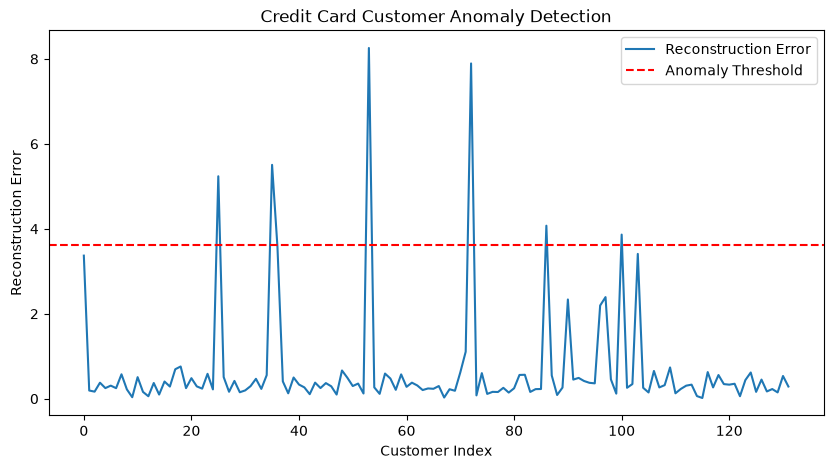

In [15]:
# Plot reconstruction errors
plt.figure(figsize=(10, 5))

plt.plot(
    reconstruction_error,
    label='Reconstruction Error'
)

plt.axhline(
    y=threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title("Credit Card Customer Anomaly Detection")
plt.xlabel("Customer Index")
plt.ylabel("Reconstruction Error")

plt.legend()
plt.show()